In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

d = fetch_olivetti_faces()
X, y = d.images, d.target

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


In [ ]:
X = np.repeat(X[..., None], 3, -1)
X = tf.image.resize(X, (96, 96)).numpy() * 255

In [ ]:
x1, x2, y1, y2 = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=42)

In [ ]:
b = tf.keras.applications.MobileNetV2(
    input_shape=(96,96,3), include_top=False, weights='imagenet')
b.trainable = False

m = tf.keras.Sequential([
    tf.keras.Input((96,96,3)),
    tf.keras.layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input),
    b, tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(40, activation='softmax')
])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
m.compile(optimizer='adam',
          loss='sparse_categorical_crossentropy',
          metrics=['accuracy'])

m.fit(x1, y1, epochs=5, validation_split=.2)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 626ms/step - accuracy: 0.0859 - loss: 4.0517 - val_accuracy: 0.1250 - val_loss: 3.5341
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 374ms/step - accuracy: 0.3203 - loss: 2.6788 - val_accuracy: 0.2656 - val_loss: 2.8523
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 292ms/step - accuracy: 0.6484 - loss: 1.8305 - val_accuracy: 0.5625 - val_loss: 2.1447
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 267ms/step - accuracy: 0.8242 - loss: 1.2534 - val_accuracy: 0.6719 - val_loss: 1.7266
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 323ms/step - accuracy: 0.9297 - loss: 0.8559 - val_accuracy: 0.7344 - val_loss: 1.4268


In [ ]:
p = m.predict(x2).argmax(axis=1)
print(classification_report(y2, p, zero_division=0))

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.50      0.50      0.50         2
           2       0.00      0.00      0.00         2
           3       1.00      0.50      0.67         2
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         2
           6       0.00      0.00      0.00         2
           7       0.50      0.50      0.50         2
           8       0.50      1.00      0.67         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       0.00      0.00      0.00         2
          12       0.00      0.00      0.00         2
          13       1.00      1.00      1.00         2
          14       1.00      0.50      0.67         2
          15       0.67      1.00      0.80         2
          16       0.67      1.00      0.80  

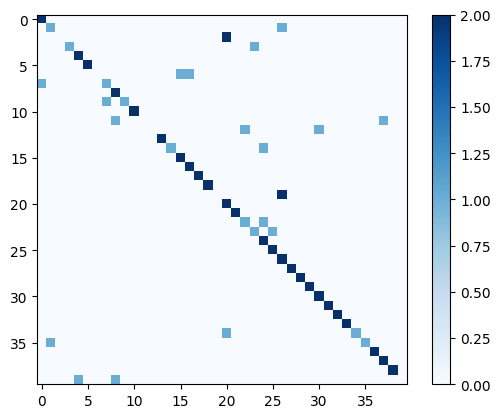

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(confusion_matrix(y2, p), cmap='Blues')
plt.colorbar()
plt.show()